# Flag Check & EDA (exploratory file)

`problem` should mark exactly the tests starting in the documented window (2013-06-25 to 2014-01-10)
- Outcome: Total Packages: 18,388, Total Unique Tests: 3,823 & 1,050 tests flagged

In [2]:
import pandas as pd

df = pd.read_csv("../data/clean/upworthy-archive-exploratory-packages-03.12.2020 (1).csv", parse_dates=["created_at", "test_start"])
df.shape               


(22666, 18)

In [3]:
tests = df.groupby("clickability_test_id").agg(
    start = ("test_start", "first"),
    problem = ("problem", "first"),
    n_packages = ("clicks", "size"),   
    
)
tests["problem"].sum()

1050

In [4]:
df.groupby("clickability_test_id")["problem"].nunique().max()

1

In [5]:
flagged = tests[tests["problem"] == 1]["start"]
flagged.min(), flagged.max()

('2013-06-25 03:38:33.509000+00:00', '2014-01-10 20:40:44.428000+00:00')

In [6]:
tests.sort_values("start").query("problem == 0").loc[lambda t: t["start"] < "2013-06-25"].tail(3)


,start,problem,n_packages
clickability_test_id,,,
51c7b78f9e61d4d06c0040db,2013-06-24 03:08:24.803000+00:00,0,4
51c8cc33bd57ec06e200319e,2013-06-24 22:46:35.771000+00:00,0,4
51c8cece234062bbdd003366,2013-06-24 22:57:41.848000+00:00,0,4


In [7]:
tests.sort_values("start").query("problem == 0").loc[lambda t: t["start"] >= "2014-01-11"].head(3)

,start,problem,n_packages
clickability_test_id,,,
52d0ad1b1229172bb2000a47,2014-01-11 02:32:34.622000+00:00,0,2
52d0ce5ddce55b11c50004b9,2014-01-11 04:55:20.697000+00:00,0,4
52d1c8cb011cf1f8ca001a37,2014-01-11 22:43:00.479000+00:00,0,4


## 1. Packages per test
Is group size uniform?

 - Outcome: 2 to 14 packages per test, 4 being the most common (43%) and 87% having 4-6        packages 
 - mean of 4.8 and median of 5
   

In [9]:
clean = df[df["problem"] == 0].copy()
pkg_per_test = clean.groupby("clickability_test_id").size()
print(f"Total Packages: {pkg_per_test.sum()}, Total Unique Tests: {len(pkg_per_test)}")

Total Packages: 18388, Total Unique Tests: 3823


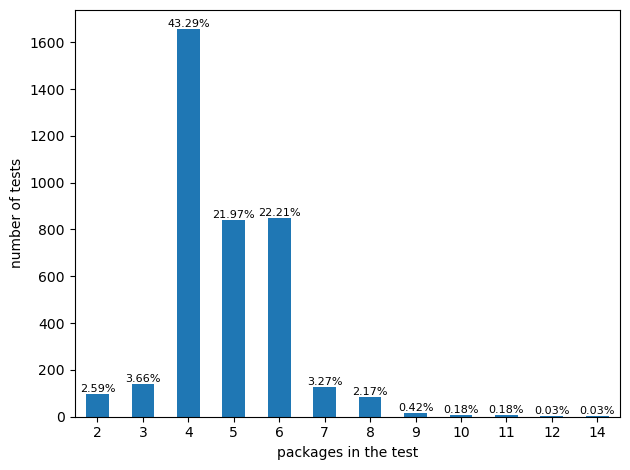

In [10]:
import matplotlib.pyplot as plt

counts = pkg_per_test.value_counts().sort_index()
pct = counts / counts.sum() * 100
bar_plot_counts = counts.plot(kind = "bar")
bar_plot_counts.bar_label(bar_plot_counts.containers[0], labels = [f"{p:.2f}%" for p in pct], fontsize=8)

bar_plot_counts.set_xlabel("packages in the test")
bar_plot_counts.set_ylabel("number of tests")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../reports/figures/packages_per_test.png", dpi=150)
plt.show()

In [11]:
pkg_per_test.describe()

count    3823.000000
mean        4.809835
std         1.240005
min         2.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        14.000000
dtype: float64

## 2. Impressions Per Package
 - Outcome: 3,118 median impressions per pakcages
 - 13 packages (0.07%) under 1,000 impressions

In [13]:
clean["impressions"].describe()

count    18388.000000
mean      3490.771101
std       1273.831005
min         13.000000
25%       2768.000000
50%       3118.000000
75%       4031.250000
max      25314.000000
Name: impressions, dtype: float64

In [14]:
clean["ctr"] = clean["clicks"] / clean["impressions"]
print(clean["ctr"].describe())

count    18388.000000
mean         0.013620
std          0.009928
min          0.000000
25%          0.006724
50%          0.011131
75%          0.017527
max          0.122842
Name: ctr, dtype: float64


In [15]:
n_small = (clean["impressions"] < 1000).sum()
print(f"packages under 1,000 impressions: {n_small} ({n_small / len(clean):.2%})")

packages under 1,000 impressions: 13 (0.07%)


## 3. Click rate per package
 - Typical rate and noise level:
    - median 1.11% | right-skewed
    - noise for one package: ~ 0.19 pp & the observed spread (std of ctr) is 0.99 pp
      $$SE = \sqrt{\frac{p(1-p)}{n}}$$

      where as: p = 1.11% (median click rate) and n = 3,118 (median impressions)

      $$SE = \sqrt{\frac{0.0111 \times 0.9889}{3118}} \approx 0.00188 = 0.19\ \text{pp}$$
      

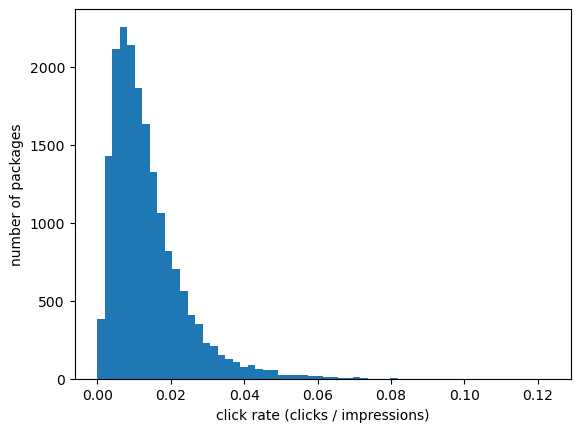

In [17]:
ctr_plot = clean["ctr"].plot(kind = "hist", bins = 60)
ctr_plot.set_xlabel("click rate (clicks / impressions)")
ctr_plot.set_ylabel("number of packages")
plt.show()


## 4. Base rate across tests
Do tests share one base rate?
No. The SD across tests is 0.94 pp, about 5× the 0.19 pp noise of a single package (0.94 / 0.19), and per test noise is smaller still.

 - each test's base rate is its pooled click rate (total    clicks / total    impressions across its packages).
 - sampling noise in that rate follows

   - $$SE = \sqrt{\frac{p(1-p)}{n}}$$


 - Outcome: per test CTR have median of 1.16% & SD 0.94 pp
    - A per test prior centers each test on its own rate and uses a              narrower, shared spread of variants around it. That is the right ` true spread of rates ` for the comparison that matters.
    -  $$w = \frac{\tau^2}{\tau^2 + \sigma^2}$$ 

In [19]:
test_ctr = clean.groupby("clickability_test_id")[["clicks", "impressions"]].sum()
test_ctr["ctr"] = test_ctr["clicks"] / test_ctr["impressions"]
print(test_ctr["ctr"].describe())

count    3823.000000
mean        0.013837
std         0.009396
min         0.000000
25%         0.007393
50%         0.011565
75%         0.017683
max         0.086927
Name: ctr, dtype: float64


days with data: 554
count    554.000000
mean       1.499860
std        0.776575
min        0.268817
25%        1.023981
50%        1.305605
75%        1.811113
max        7.134332
Name: ctr, dtype: float64


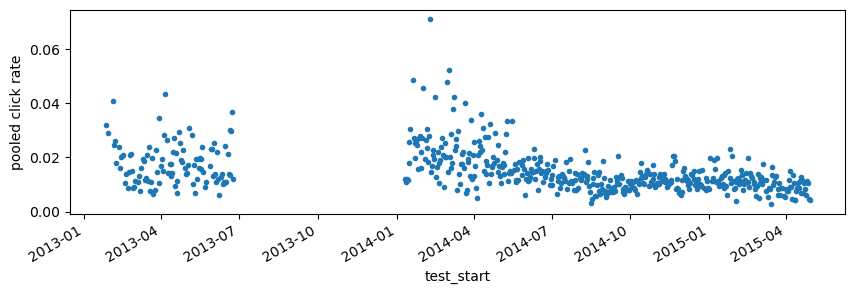

In [20]:
# test_start is stored as text like "2013-06-25 03:38:33+00:00" the first 10 characters are the date
day = clean["test_start"].str[:10]

daily = clean.groupby(day).agg(
    clicks = ("clicks", "sum"),
    impressions = ("impressions", "sum"),
    n_packages = ("clicks", "size"),)
daily.index = pd.to_datetime(daily.index) # real dates

daily["ctr"] = daily["clicks"] / daily["impressions"] # pool first, then divide, so busy packages count in proportion to their traffic


print(f"days with data: {len(daily)}")
print((daily["ctr"] * 100).describe()) # in percent

daily["ctr"].plot(style=".", figsize=(10, 3))   # dots, because days with few tests are noisy and a line would overstate smoothness
plt.ylabel("pooled click rate")
plt.show()

## 5. Zero click packages
Should be retained or excluded?
A: We retain them since they won't be top / winner packages we will deal with anyway
- found 1 test with zero overall click & 10 zero click packages


In [22]:
# Zero clicks
n_zero_tests = (test_ctr["clicks"] == 0).sum()
n_zero_pkgs = (clean["clicks"] == 0).sum()

print(f"tests with zero clicks overall: {n_zero_tests}")
print(f"packages with zero clicks: {n_zero_pkgs} ({n_zero_pkgs / len(clean):.2%})")
print(clean.loc[clean["clicks"] == 0, "impressions"].sort_values())


tests with zero clicks overall: 1
packages with zero clicks: 10 (0.05%)
13204      13
13137      21
12164      24
13364      28
2372      764
2211     1923
1791     2464
16642    4553
16640    4595
7661     4992
Name: impressions, dtype: int64


## 6. Next, sample ratio mismatch (SRM) - a check of whether randomization works as designed (equal impressions distribution in this case)
 - in case few tests fail, flag them and if most fails we have to check how archive of Upworthy dealt with it. 

    $$\chi^2 = \sum\frac{(\text{observed} - \text{expected})^2}{\text{expected}}$$
    where as,
    $$\text{expected} = \frac{\sum \text{impressions}}{\text{number of packages}}$$

   - Outcome: 18/3,823 tests fail at p < 0.001 (about 4 expected) which is flagged as `srm_fail`and we keep it for main analysis
   - there is a slight tilt in bar plot. Although a flat plot was my original expectation

tests with p < 0.001: 18 of 3823 (about 4 expected by chance)


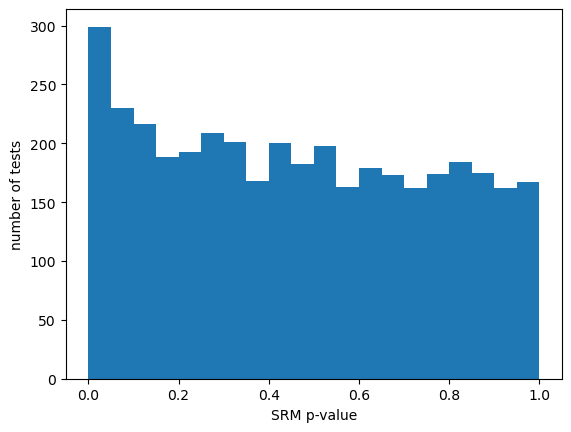

In [24]:
from scipy.stats import chisquare
#chisquare() compares the observed counts against an equal split by default
#its the equal allocation null hypothesis and p value is the test result

srm_p = clean.groupby("clickability_test_id")["impressions"].apply(lambda s: chisquare(s).pvalue)
n_fail = (srm_p < 0.001).sum()
print(f"tests with p < 0.001: {n_fail} of {len(srm_p)} (about {len(srm_p) * 0.001:.0f} expected by chance)")

srm_p.plot(kind = "hist", bins=20)
plt.xlabel("SRM p-value")
plt.ylabel("number of tests")
plt.show()



In [25]:
ratio = clean.groupby("clickability_test_id")["impressions"].agg(lambda s: s.max() / s.min())
print(ratio.describe())

count    3823.000000
mean        1.046134
std         0.200157
min         1.000430
25%         1.028944
50%         1.040339
75%         1.054632
max        13.309148
Name: impressions, dtype: float64


In [26]:
srm_fail_ids = srm_p[srm_p < 0.001].index
clean["srm_fail"] = clean["clickability_test_id"].isin(srm_fail_ids).astype(int)
print(len(srm_fail_ids), clean["srm_fail"].sum()) # failing tests, packages in them

18 83
